# Phase 3.1: Cài đặt mạng CNN cơ bản nhận dạng ảnh trên tập dữ liệu CIFAR-10

> **Môi trường khuyến nghị:** Google Colab (`Runtime → Change runtime type → T4 GPU`) hoặc Kaggle (`Settings → Accelerator → GPU T4 / P100`).
> **Framework:** PyTorch + Torchvision.

---

## Mục tiêu bài thực hành
1. **Khám phá dữ liệu CIFAR-10:** Hiểu cấu trúc bộ dữ liệu 60,000 ảnh màu RGB kích thước $32 \times 32$ thuộc 10 lớp đối tượng.
2. **Tiền xử lý & Tăng cường dữ liệu (Data Augmentation):** Tách tập Train/Validation cân bằng theo lớp (*Stratified Split*), chuẩn hóa kênh màu và áp dụng các phép biến đổi tăng cường dữ liệu.
3. **Xây dựng mạng CNN cơ bản từ đầu (from scratch):**
   - **Mô hình A (`SimpleCNN` — Baseline):** Mạng tích chập 3 tầng cơ bản (không BatchNorm, không Dropout, không Data Augmentation) nhằm quan sát trực tiếp hiện tượng **Overfitting**.
   - **Mô hình B (`BasicCNN` — Mô hình chính):** Mạng CNN 3 khối tích chập chuẩn VGG-style (`Conv3×3 → BatchNorm → ReLU` × 2 + `MaxPool2d` + `Dropout2d`) kết hợp Data Augmentation, `AdamW`, `Label Smoothing` và `CosineAnnealingLR`.
4. **Đánh giá & Phân tích sâu:** So sánh Learning Curves, độ chính xác trên tập Test (10,000 ảnh), Classification Report từng lớp, Confusion Matrix, trực quan hóa **bộ lọc Conv1**, **Feature Maps qua các tầng** và phân tích các mẫu dự đoán sai (*Error Analysis*).
5. **Xuất kết quả báo cáo:** Tự động lưu toàn bộ biểu đồ (`.png`) và file tổng hợp chỉ số (`metrics_summary.json`) để đưa lên GitHub báo cáo.

---

## Tóm tắt lý thuyết CNN cơ bản
Mạng nơ-ron tích chập (**Convolutional Neural Network — CNN**) tận dụng 2 giả định quy nạp (*inductive biases*) đặc trưng của dữ liệu ảnh:
- **Tính cục bộ (Locality):** Các pixel lân cận có tương quan mạnh với nhau; bộ lọc tích chập kích thước nhỏ ($3 \times 3$) trích xuất đặc trưng cục bộ như cạnh, góc, kết cấu.
- **Bất biến dịch chuyển (Translation Equivariance & Weight Sharing):** Cùng một bộ lọc được trượt trên toàn bộ ảnh, giúp giảm mạnh số tham số so với mạng kết nối đầy đủ (MLP).

Với đầu vào có kích thước không gian $H_{\text{in}} \times W_{\text{in}}$, kernel $K$, padding $P$ và stride $S$, kích thước đầu ra của tầng tích chập là:
$$H_{\text{out}} = \left\lfloor \frac{H_{\text{in}} + 2P - K}{S} \right\rfloor + 1$$
Khi sử dụng $K=3, P=1, S=1$, kích thước không gian được **giữ nguyên** qua tầng `Conv2d` và chỉ giảm một nửa sau mỗi tầng `MaxPool2d(2, 2)`.

In [1]:
# =============================================================================
# 0. THIẾT LẬP MÔI TRƯỜNG, SEED & CẤU HÌNH THỰC NGHIỆM
# =============================================================================
import contextlib
import json
import os
import random
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedShuffleSplit
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

# Tránh cảnh báo chờ HF_TOKEN khi chạy qua Colab CLI / môi trường không có Colab UI Secrets
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")

# Cấu hình font & giao diện biểu đồ
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
sns.set_style("whitegrid")

# Kiểm tra môi trường chạy
IN_COLAB = "COLAB_GPU" in os.environ or os.path.exists("/content")
IN_KAGGLE = os.path.exists("/kaggle/working")
ENV_NAME = "Google Colab" if IN_COLAB else ("Kaggle" if IN_KAGGLE else "Local")

# Cấu hình tập trung (có thể tùy chỉnh nhanh tại đây)
CONFIG = {
    "seed": 42,
    "data_dir": "./data",
    "output_dir": "./outputs/cnn_cifar10",
    "val_ratio": 0.1,               # 45,000 train / 5,000 val / 10,000 test
    "batch_size": 128,
    "num_workers": 0 if os.name == "nt" else min(2, os.cpu_count() or 2),
    # Thực nghiệm A: Baseline SimpleCNN (chứng minh overfitting khi thiếu BN/Aug)
    "run_baseline_comparison": True,
    "baseline_epochs": 15,
    "baseline_lr": 1e-3,
    # Thực nghiệm B: BasicCNN chính (BatchNorm + Dropout + Augmentation + CosineLR)
    "improved_epochs": 35,
    "improved_lr": 1e-3,
    "weight_decay": 5e-4,
    "label_smoothing": 0.05,
}

OUTPUT_DIR = Path(CONFIG["output_dir"])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def seed_everything(seed: int = 42) -> None:
    """Cố định toàn bộ random seed để đảm bảo khả năng tái lập kết quả."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(CONFIG["seed"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"

print(f"Môi trường chạy   : {ENV_NAME}")
print(f"PyTorch version   : {torch.__version__} | Torchvision: {torchvision.__version__}")
print(f"Thiết bị tính toán: {device}")
if device.type == "cuda":
    print(f"GPU               : {torch.cuda.get_device_name(0)}")
    print(f"VRAM              : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("Cảnh báo: Chưa bật GPU! Hãy bật T4/P100 GPU trên Colab/Kaggle để huấn luyện nhanh hơn.")

Môi trường chạy   : Google Colab
PyTorch version   : 2.14.1+cu130 | Torchvision: 0.29.1+cu130
Thiết bị tính toán: cuda
GPU               : Tesla T4
VRAM              : 15.64 GB


## Phần 1: Tải và Khám phá bộ dữ liệu CIFAR-10

**CIFAR-10** (Canadian Institute For Advanced Research) gồm **60,000 ảnh màu RGB** kích thước $32 \times 32$, chia đều cho **10 lớp**:
`airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship`, `truck`.

- **Tập Train gốc:** 50,000 ảnh (5,000 ảnh/lớp) → tách theo **Stratified Split** thành **45,000 Train** (4,500 ảnh/lớp) và **5,000 Validation** (500 ảnh/lớp).
- **Tập Test:** 10,000 ảnh (1,000 ảnh/lớp), chỉ dùng để đánh giá cuối cùng sau khi chọn mô hình tốt nhất trên Validation.

Nguồn tải dữ liệu: Hugging Face Datasets (uoft-cs/cifar10)
Danh sách 10 lớp CIFAR-10: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Kích thước train gốc: (50000, 32, 32, 3) (dtype=uint8)
Kích thước test gốc : (10000, 32, 32, 3) (dtype=uint8)

Số lượng mẫu sau khi chia:
  - Train      : 45,000 ảnh (4500 ảnh/lớp)
  - Validation : 5,000 ảnh (500 ảnh/lớp)
  - Test       : 10,000 ảnh (1000 ảnh/lớp)



Thống kê tập Train -> Mean: (0.4909, 0.4817, 0.4461), Std: (0.247, 0.2434, 0.2615)


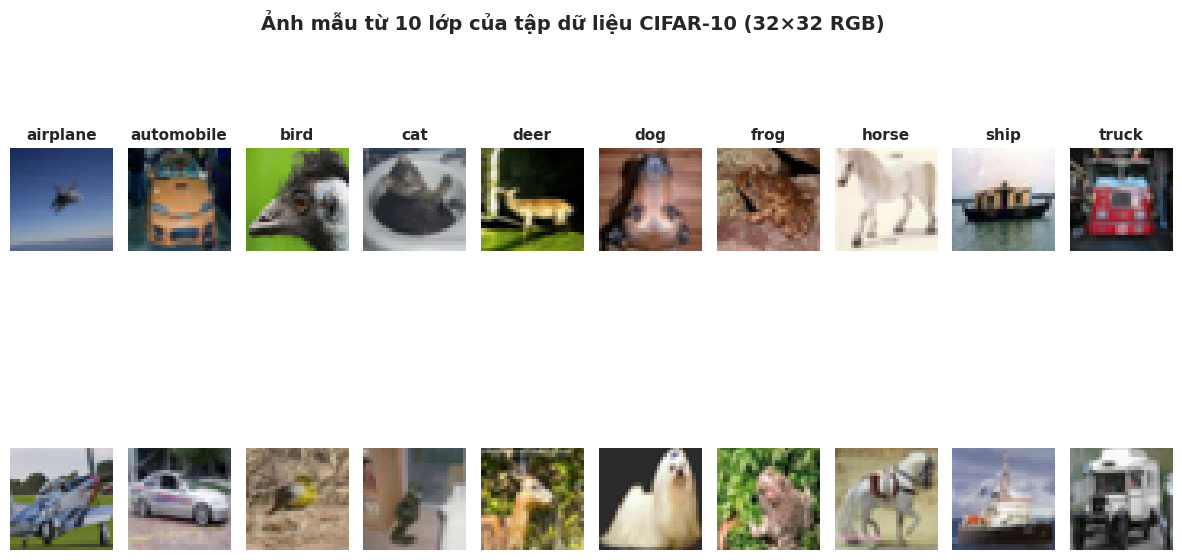

,Lớp,Train,Validation,Test
0,airplane,4500,500,1000
1,automobile,4500,500,1000
2,bird,4500,500,1000
3,cat,4500,500,1000
4,deer,4500,500,1000
5,dog,4500,500,1000
6,frog,4500,500,1000
7,horse,4500,500,1000
8,ship,4500,500,1000
9,truck,4500,500,1000


In [2]:
# =============================================================================
# 1. TẢI DỮ LIỆU CIFAR-10 & PHÂN CHIA TRAIN / VAL / TEST CÂN BẰNG (STRATIFIED)
# =============================================================================
class HFCifarDataset(Dataset):
    """Tải CIFAR-10 qua Hugging Face Datasets (nhanh hơn nhiều so với tải trực tiếp cs.toronto.edu)."""

    def __init__(self, hf_split, label_col: str = "label"):
        self.classes = list(hf_split.features[label_col].names)
        self.targets = [int(x) for x in hf_split[label_col]]
        self.data = np.stack([np.asarray(img, dtype=np.uint8) for img in hf_split["img"]], axis=0)

    def __len__(self) -> int:
        return len(self.targets)

    def __getitem__(self, idx: int):
        return Image.fromarray(self.data[idx]), self.targets[idx]


try:
    from datasets import load_dataset

    hf_cifar10 = load_dataset("uoft-cs/cifar10")
    train_raw = HFCifarDataset(hf_cifar10["train"], label_col="label")
    test_raw = HFCifarDataset(hf_cifar10["test"], label_col="label")
    print("Nguồn tải dữ liệu: Hugging Face Datasets (uoft-cs/cifar10)")
except Exception as err:
    print(f"Không tải được qua Hugging Face ({err}), chuyển sang torchvision.datasets.CIFAR10...")
    train_raw = torchvision.datasets.CIFAR10(root=CONFIG["data_dir"], train=True, download=True)
    test_raw = torchvision.datasets.CIFAR10(root=CONFIG["data_dir"], train=False, download=True)

CLASSES = train_raw.classes
NUM_CLASSES = len(CLASSES)
print(f"Danh sách {NUM_CLASSES} lớp CIFAR-10: {CLASSES}")
print(f"Kích thước train gốc: {train_raw.data.shape} (dtype={train_raw.data.dtype})")
print(f"Kích thước test gốc : {test_raw.data.shape} (dtype={test_raw.data.dtype})")

# Chia Train / Validation cân bằng theo từng lớp
sss = StratifiedShuffleSplit(
    n_splits=1, test_size=CONFIG["val_ratio"], random_state=CONFIG["seed"]
)
train_targets = np.array(train_raw.targets)
train_idx, val_idx = next(sss.split(np.zeros(len(train_targets)), train_targets))

print(f"\nSố lượng mẫu sau khi chia:")
print(f"  - Train      : {len(train_idx):,} ảnh ({len(train_idx)//NUM_CLASSES} ảnh/lớp)")
print(f"  - Validation : {len(val_idx):,} ảnh ({len(val_idx)//NUM_CLASSES} ảnh/lớp)")
print(f"  - Test       : {len(test_raw):,} ảnh ({len(test_raw)//NUM_CLASSES} ảnh/lớp)")

# Tính Mean và Std thực tế trên tập Train (tránh rò rỉ dữ liệu từ Val/Test)
train_pixels = train_raw.data[train_idx] / 255.0
CIFAR10_MEAN = tuple(train_pixels.mean(axis=(0, 1, 2)).round(4).tolist())
CIFAR10_STD = tuple(train_pixels.std(axis=(0, 1, 2)).round(4).tolist())
print(f"\nThống kê tập Train -> Mean: {CIFAR10_MEAN}, Std: {CIFAR10_STD}")

# Trực quan hóa 2 ảnh mẫu cho mỗi lớp + biểu đồ phân bố lớp
fig = plt.figure(figsize=(15, 7))
gs = fig.add_gridspec(2, 10, height_ratios=[1, 1], hspace=0.25, wspace=0.15)
for cls_id, cls_name in enumerate(CLASSES):
    cls_indices = train_idx[train_targets[train_idx] == cls_id][:2]
    for row_i, sample_i in enumerate(cls_indices):
        ax = fig.add_subplot(gs[row_i, cls_id])
        ax.imshow(train_raw.data[sample_i])
        ax.axis("off")
        if row_i == 0:
            ax.set_title(cls_name, fontsize=11, fontweight="bold")
fig.suptitle("Ảnh mẫu từ 10 lớp của tập dữ liệu CIFAR-10 (32×32 RGB)", fontsize=14, fontweight="bold", y=0.98)
plt.savefig(OUTPUT_DIR / "01_cifar10_samples.png", dpi=150, bbox_inches="tight")
plt.show()

# Kiểm tra trực quan cân bằng nhãn giữa Train / Val / Test
counts_df = pd.DataFrame({
    "Lớp": CLASSES,
    "Train": np.bincount(train_targets[train_idx], minlength=NUM_CLASSES),
    "Validation": np.bincount(train_targets[val_idx], minlength=NUM_CLASSES),
    "Test": np.bincount(np.array(test_raw.targets), minlength=NUM_CLASSES),
})
display(counts_df)

## Phần 2: Tiền xử lý & Tăng cường dữ liệu (Data Augmentation)

Để tránh rò rỉ phép biến đổi (*transform leakage*) giữa tập Train và Validation khi dùng cùng một đối tượng `CIFAR10`, ta xây dựng lớp `TransformedSubset` tách biệt hoàn toàn pipeline biến đổi:
- **Tập Train (có Augmentation):**
  - `RandomCrop(32, padding=4, padding_mode="reflect")`: dịch chuyển nhẹ đối tượng giúp mạng học tính bất biến vị trí.
  - `RandomHorizontalFlip(p=0.5)`: lật ngang ngẫu nhiên (hợp lệ với cả 10 lớp đối tượng CIFAR-10).
  - `ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15)`: tăng độ bền vững trước thay đổi ánh sáng.
  - `ToTensor()` + `Normalize(mean, std)` + `RandomErasing(p=0.2)`: che ngẫu nhiên một vùng nhỏ (tương tự Cutout) giúp mạng không phụ thuộc vào một đặc trưng duy nhất.
- **Tập Validation & Test:** Chỉ `ToTensor()` + `Normalize(mean, std)`.

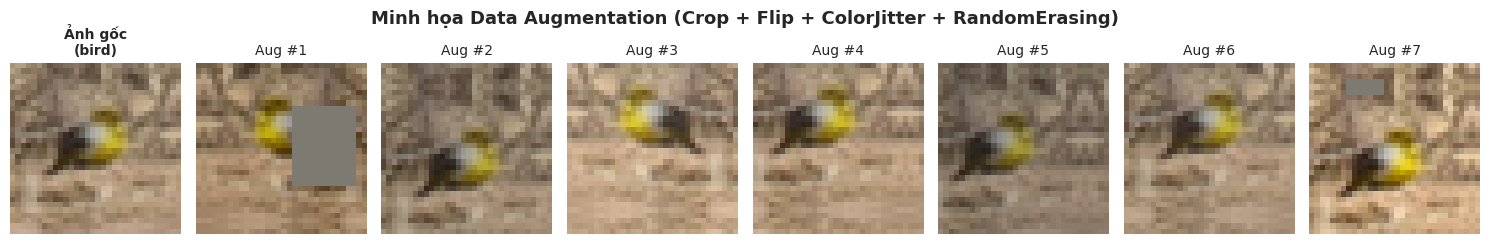

In [3]:
# =============================================================================
# 2. PIPELINE TIỀN XỬ LÝ, DATA AUGMENTATION & DATALOADER
# =============================================================================
class TransformedSubset(Dataset):
    """Wrapper tách biệt hoàn toàn transform cho từng tập con (Train / Val)."""

    def __init__(self, base_dataset: Dataset, indices, transform=None):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.indices)

    def __getitem__(self, idx: int):
        img, label = self.base_dataset[self.indices[idx]]
        if self.transform is not None:
            img = self.transform(img)
        return img, label


# Transform cơ bản (dùng cho Baseline, Validation và Test)
eval_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

# Transform có Data Augmentation (dùng cho BasicCNN chính)
train_aug_transform = T.Compose([
    T.RandomCrop(32, padding=4, padding_mode="reflect"),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    T.ToTensor(),
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
    T.RandomErasing(p=0.2, scale=(0.02, 0.2), ratio=(0.3, 3.3)),
])

# Khởi tạo Datasets
train_plain_ds = TransformedSubset(train_raw, train_idx, transform=eval_transform)
train_aug_ds = TransformedSubset(train_raw, train_idx, transform=train_aug_transform)
val_ds = TransformedSubset(train_raw, val_idx, transform=eval_transform)
test_ds = TransformedSubset(test_raw, range(len(test_raw)), transform=eval_transform)

# Khởi tạo DataLoaders
loader_kwargs = {
    "batch_size": CONFIG["batch_size"],
    "num_workers": CONFIG["num_workers"],
    "pin_memory": (device.type == "cuda"),
    "persistent_workers": (CONFIG["num_workers"] > 0),
}
train_plain_loader = DataLoader(train_plain_ds, shuffle=True, **loader_kwargs)
train_aug_loader = DataLoader(train_aug_ds, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_ds, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kwargs)


def denormalize(tensor: torch.Tensor, mean=CIFAR10_MEAN, std=CIFAR10_STD) -> np.ndarray:
    """Chuyển tensor đã chuẩn hóa (C, H, W) về ảnh numpy [0, 1] dạng (H, W, C)."""
    mean_t = torch.tensor(mean).view(3, 1, 1)
    std_t = torch.tensor(std).view(3, 1, 1)
    img = tensor.detach().cpu() * std_t + mean_t
    return img.clamp(0.0, 1.0).permute(1, 2, 0).numpy()


# Minh họa tác dụng của Data Augmentation trên 1 ảnh mẫu
sample_pil, sample_lbl = train_raw[train_idx[7]]
fig, axes = plt.subplots(1, 8, figsize=(15, 2.5))
axes[0].imshow(sample_pil)
axes[0].set_title(f"Ảnh gốc\n({CLASSES[sample_lbl]})", fontweight="bold", fontsize=10)
axes[0].axis("off")

for i in range(1, 8):
    aug_tensor = train_aug_transform(sample_pil)
    axes[i].imshow(denormalize(aug_tensor))
    axes[i].set_title(f"Aug #{i}", fontsize=10)
    axes[i].axis("off")

plt.suptitle("Minh họa Data Augmentation (Crop + Flip + ColorJitter + RandomErasing)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_data_augmentation.png", dpi=150, bbox_inches="tight")
plt.show()

## Phần 3: Thiết kế kiến trúc mạng CNN cơ bản

Ta xây dựng 2 kiến trúc CNN từ đầu để so sánh trực tiếp:

### 1. `SimpleCNN` (Baseline thuần túy)
- 3 tầng tích chập đơn lẻ: `Conv(3→32) → ReLU → MaxPool` → `Conv(32→64) → ReLU → MaxPool` → `Conv(64→128) → ReLU → MaxPool`
- Bộ phân loại: `Flatten(2048) → Linear(2048→256) → ReLU → Linear(256→10)`
- Không có BatchNorm, không Dropout, huấn luyện trên dữ liệu chưa augment → dùng làm mốc đối chứng.

### 2. `BasicCNN` (Mô hình CNN cơ bản hoàn chỉnh — VGG-style)
| Khối | Các tầng thành phần | Kích thước đầu ra |
|---|---|---|
| Input | Ảnh RGB chuẩn hóa | $3 \times 32 \times 32$ |
| **Block 1** | $2 \times [\text{Conv } 3\times3\ (32) + \text{BN} + \text{ReLU}] + \text{MaxPool}(2) + \text{Dropout2d}(0.1)$ | $32 \times 16 \times 16$ |
| **Block 2** | $2 \times [\text{Conv } 3\times3\ (64) + \text{BN} + \text{ReLU}] + \text{MaxPool}(2) + \text{Dropout2d}(0.2)$ | $64 \times 8 \times 8$ |
| **Block 3** | $2 \times [\text{Conv } 3\times3\ (128) + \text{BN} + \text{ReLU}] + \text{MaxPool}(2) + \text{Dropout2d}(0.3)$ | $128 \times 4 \times 4$ |
| **Classifier** | $\text{Flatten}(2048) \to \text{Linear}(256) + \text{BN1d} + \text{ReLU} + \text{Dropout}(0.5) \to \text{Linear}(10)$ | $10$ logits |

> Việc chồng 2 lớp tích chập $3 \times 3$ liên tiếp mang lại **vùng tiếp nhận (receptive field)** tương đương bộ lọc $5 \times 5$, nhưng ít tham số hơn và tăng tính phi tuyến nhờ 2 hàm kích hoạt `ReLU`.

In [4]:
# =============================================================================
# 3. ĐỊNH NGHĨA KIẾN TRÚC MẠNG SimpleCNN (BASELINE) & BasicCNN (CHÍNH)
# =============================================================================
class SimpleCNN(nn.Module):
    """Mạng CNN 3 tầng đơn giản làm Baseline (không BatchNorm, không Dropout)."""

    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),          # 32x16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),          # 64x8x8
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),          # 128x4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Linear(256, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        return self.classifier(x)


class BasicCNN(nn.Module):
    """Mạng CNN cơ bản 3 khối tích chập (VGG-style) kèm BatchNorm & Dropout."""

    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.block1 = self._make_block(3, 32, dropout_p=0.10)    # -> 32x16x16
        self.block2 = self._make_block(32, 64, dropout_p=0.20)   # -> 64x8x8
        self.block3 = self._make_block(64, 128, dropout_p=0.30)  # -> 128x4x4

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.50),
            nn.Linear(256, num_classes),
        )
        self._init_weights()

    @staticmethod
    def _make_block(in_ch: int, out_ch: int, dropout_p: float) -> nn.Sequential:
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(dropout_p),
        )

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return self.classifier(x)

    @torch.no_grad()
    def extract_feature_maps(self, x: torch.Tensor) -> dict:
        """Trích xuất feature maps trung gian qua 3 khối để trực quan hóa."""
        f1 = self.block1(x)
        f2 = self.block2(f1)
        f3 = self.block3(f2)
        return {"Block 1 (32×16×16)": f1, "Block 2 (64×8×8)": f2, "Block 3 (128×4×4)": f3}


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Kiểm tra kiến trúc & kích thước tensor đi qua từng khối
dummy_x = torch.randn(2, 3, 32, 32)
tmp_simple = SimpleCNN(NUM_CLASSES)
tmp_basic = BasicCNN(NUM_CLASSES)

print(f"SimpleCNN trainable params : {count_parameters(tmp_simple):,}")
print(f"BasicCNN  trainable params : {count_parameters(tmp_basic):,}")

fmaps = tmp_basic.extract_feature_maps(dummy_x)
print("\nKiểm tra kích thước tensor qua BasicCNN (batch_size=2):")
print(f"  Input   : {tuple(dummy_x.shape)}")
for name, feat in fmaps.items():
    print(f"  {name}: {tuple(feat.shape)}")
print(f"  Logits  : {tuple(tmp_basic(dummy_x).shape)}")
del tmp_simple, tmp_basic, dummy_x, fmaps

SimpleCNN trainable params : 620,362
BasicCNN  trainable params : 815,082

Kiểm tra kích thước tensor qua BasicCNN (batch_size=2):
  Input   : (2, 3, 32, 32)
  Block 1 (32×16×16): (2, 32, 16, 16)
  Block 2 (64×8×8): (2, 64, 8, 8)
  Block 3 (128×4×4): (2, 128, 4, 4)
  Logits  : (2, 10)


## Phần 4: Xây dựng quy trình Huấn luyện & Đánh giá (Training Engine)

Quy trình huấn luyện áp dụng các kỹ thuật chuẩn thực tế:
- **Mixed Precision (`AMP FP16`)** tự động bật khi có CUDA GPU để tăng tốc huấn luyện mà vẫn giữ nguyên độ chính xác.
- **Optimizer `AdamW`** kết hợp **Weight Decay** giảm hiện tượng trọng số quá lớn.
- **Scheduler `CosineAnnealingLR`** giảm mượt tốc độ học theo đường cong cosine giúp hội tụ sâu và ổn định.
- **Best Checkpoint Saving:** Luôn lưu lại bộ trọng số đạt `val_acc` cao nhất trên tập Validation để tránh chọn nhầm epoch bị overfitting.

In [5]:
# =============================================================================
# 4. HÀM HUẤN LUYỆN VÀ ĐÁNH GIÁ DÙNG CHUNG (HỖ TRỢ AMP FP16)
# =============================================================================
def get_autocast_ctx(use_amp: bool):
    if not use_amp:
        return contextlib.nullcontext()
    if hasattr(torch, "amp") and hasattr(torch.amp, "autocast"):
        return torch.amp.autocast("cuda", enabled=True)
    return torch.cuda.amp.autocast(enabled=True)


def make_grad_scaler(use_amp: bool):
    if not use_amp:
        return None
    if hasattr(torch, "amp") and hasattr(torch.amp, "GradScaler"):
        return torch.amp.GradScaler("cuda", enabled=True)
    return torch.cuda.amp.GradScaler(enabled=True)


def train_one_epoch(model, loader, criterion, optimizer, scaler, device, use_amp):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with get_autocast_ctx(use_amp):
            logits = model(images)
            loss = criterion(logits, labels)

        if scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device, use_amp=False, return_preds=False):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with get_autocast_ctx(use_amp):
            logits = model(images)
            loss = criterion(logits, labels)

        probs = F.softmax(logits.float(), dim=1)
        preds = probs.argmax(dim=1)

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (preds == labels).sum().item()
        total += batch_size

        if return_preds:
            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())
            all_probs.append(probs.cpu().numpy())

    avg_loss = total_loss / total
    avg_acc = correct / total
    if return_preds:
        return (
            avg_loss,
            avg_acc,
            np.concatenate(all_preds),
            np.concatenate(all_labels),
            np.concatenate(all_probs),
        )
    return avg_loss, avg_acc


def fit_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    epochs: int,
    save_path: Path,
    model_title: str,
):
    scaler = make_grad_scaler(USE_AMP)
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "lr": [],
    }
    best_val_acc = 0.0
    best_epoch = 0
    start_time = time.time()

    print(f"\n{'='*72}")
    print(f"Bắt đầu huấn luyện: {model_title} ({epochs} epochs)")
    print(f"{'='*72}")

    for epoch in range(1, epochs + 1):
        ep_start = time.time()
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, USE_AMP
        )
        val_loss, val_acc = evaluate(model, val_loader, criterion, device, USE_AMP)
        current_lr = optimizer.param_groups[0]["lr"]

        if scheduler is not None:
            scheduler.step()

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(current_lr)

        marker = ""
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch
            torch.save(model.state_dict(), save_path)
            marker = "  ★ Best"

        ep_time = time.time() - ep_start
        print(
            f"Epoch {epoch:02d}/{epochs:02d} | "
            f"Train Loss: {train_loss:.4f} Acc: {train_acc*100:5.2f}% | "
            f"Val Loss: {val_loss:.4f} Acc: {val_acc*100:5.2f}% | "
            f"LR: {current_lr:.2e} | {ep_time:.1f}s{marker}"
        )

    total_time = time.time() - start_time
    print(f"{'-'*72}")
    print(
        f"Hoàn tất {model_title} trong {total_time:.1f}s | "
        f"Best Val Acc: {best_val_acc*100:.2f}% (Epoch {best_epoch})"
    )
    return history, best_val_acc, best_epoch, total_time

## Phần 5: Thực nghiệm A (Baseline) — Huấn luyện `SimpleCNN`

Trước tiên, ta huấn luyện mô hình đối chứng `SimpleCNN` trên dữ liệu gốc (không Augmentation, không BatchNorm/Dropout) để quan sát tốc độ hội tụ và khoảng cách giữa `Train Acc` và `Val Acc` (dấu hiệu **Overfitting**).

In [6]:
# =============================================================================
# 5. THỰC NGHIỆM A: BASELINE SimpleCNN (KHÔNG BN / DROPOUT / AUGMENTATION)
# =============================================================================
baseline_history = None
baseline_test_acc = None
baseline_time = None

if CONFIG["run_baseline_comparison"]:
    seed_everything(CONFIG["seed"])
    simple_model = SimpleCNN(NUM_CLASSES).to(device)
    baseline_criterion = nn.CrossEntropyLoss()
    baseline_optimizer = torch.optim.Adam(simple_model.parameters(), lr=CONFIG["baseline_lr"])
    baseline_ckpt = OUTPUT_DIR / "simple_cnn_best.pth"

    baseline_history, baseline_best_val, baseline_best_ep, baseline_time = fit_model(
        model=simple_model,
        train_loader=train_plain_loader,
        val_loader=val_loader,
        criterion=baseline_criterion,
        optimizer=baseline_optimizer,
        scheduler=None,
        epochs=CONFIG["baseline_epochs"],
        save_path=baseline_ckpt,
        model_title="SimpleCNN (Baseline)",
    )

    simple_model.load_state_dict(torch.load(baseline_ckpt, map_location=device))
    baseline_test_loss, baseline_test_acc = evaluate(
        simple_model, test_loader, baseline_criterion, device, USE_AMP
    )
    print(f"--> [Baseline SimpleCNN] Test Loss: {baseline_test_loss:.4f} | Test Acc: {baseline_test_acc*100:.2f}%")


Bắt đầu huấn luyện: SimpleCNN (Baseline) (15 epochs)


Epoch 01/15 | Train Loss: 1.4331 Acc: 47.84% | Val Loss: 1.1244 Acc: 59.40% | LR: 1.00e-03 | 11.7s  ★ Best


Epoch 02/15 | Train Loss: 0.9924 Acc: 65.08% | Val Loss: 0.9592 Acc: 64.42% | LR: 1.00e-03 | 11.0s  ★ Best


Epoch 03/15 | Train Loss: 0.8115 Acc: 71.70% | Val Loss: 0.8442 Acc: 70.08% | LR: 1.00e-03 | 10.6s  ★ Best


Epoch 04/15 | Train Loss: 0.6785 Acc: 76.28% | Val Loss: 0.7891 Acc: 72.62% | LR: 1.00e-03 | 10.3s  ★ Best


Epoch 05/15 | Train Loss: 0.5786 Acc: 79.94% | Val Loss: 0.7603 Acc: 74.26% | LR: 1.00e-03 | 10.8s  ★ Best


... (7 outputs left out)

Epoch 13/15 | Train Loss: 0.1069 Acc: 96.29% | Val Loss: 1.3015 Acc: 74.72% | LR: 1.00e-03 | 10.4s


Epoch 14/15 | Train Loss: 0.0903 Acc: 96.82% | Val Loss: 1.2325 Acc: 75.20% | LR: 1.00e-03 | 9.9s


Epoch 15/15 | Train Loss: 0.0875 Acc: 96.98% | Val Loss: 1.3581 Acc: 75.76% | LR: 1.00e-03 | 10.7s
------------------------------------------------------------------------
Hoàn tất SimpleCNN (Baseline) trong 159.8s | Best Val Acc: 75.96% (Epoch 9)


--> [Baseline SimpleCNN] Test Loss: 0.8438 | Test Acc: 75.88%


## Phần 6: Thực nghiệm B (Mô hình chính) — Huấn luyện `BasicCNN`

Bây giờ ta huấn luyện mô hình **`BasicCNN`** đầy đủ với:
- **Batch Normalization** ổn định phân phối kích hoạt và cho phép hội tụ nhanh hơn.
- **Dropout2d & Dropout** chống đồng thích nghi (*co-adaptation*) giữa các nơ-ron.
- **Data Augmentation** mở rộng đa dạng tập huấn luyện.
- **AdamW + Label Smoothing (0.05) + CosineAnnealingLR** giúp mô hình khái quát hóa tốt hơn trên tập Test.

In [7]:
# =============================================================================
# 6. THỰC NGHIỆM B: BasicCNN CHÍNH (BATCHNORM + DROPOUT + AUGMENTATION)
# =============================================================================
seed_everything(CONFIG["seed"])
basic_model = BasicCNN(NUM_CLASSES).to(device)

criterion_train = nn.CrossEntropyLoss(label_smoothing=CONFIG["label_smoothing"])
criterion_eval = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    basic_model.parameters(),
    lr=CONFIG["improved_lr"],
    weight_decay=CONFIG["weight_decay"],
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=CONFIG["improved_epochs"], eta_min=1e-5
)
best_ckpt_path = OUTPUT_DIR / "basic_cnn_best.pth"

basic_history, basic_best_val, basic_best_ep, basic_time = fit_model(
    model=basic_model,
    train_loader=train_aug_loader,
    val_loader=val_loader,
    criterion=criterion_train,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=CONFIG["improved_epochs"],
    save_path=best_ckpt_path,
    model_title="BasicCNN (BN + Dropout + Augmentation)",
)


Bắt đầu huấn luyện: BasicCNN (BN + Dropout + Augmentation) (35 epochs)


Epoch 01/35 | Train Loss: 1.9259 Acc: 34.01% | Val Loss: 1.4429 Acc: 51.88% | LR: 1.00e-03 | 36.3s  ★ Best


Epoch 02/35 | Train Loss: 1.5498 Acc: 48.06% | Val Loss: 1.2250 Acc: 61.06% | LR: 9.98e-04 | 35.1s  ★ Best


Epoch 03/35 | Train Loss: 1.3889 Acc: 55.51% | Val Loss: 1.1270 Acc: 66.30% | LR: 9.92e-04 | 35.5s  ★ Best


Epoch 04/35 | Train Loss: 1.3005 Acc: 59.02% | Val Loss: 1.0410 Acc: 69.70% | LR: 9.82e-04 | 36.0s  ★ Best


Epoch 05/35 | Train Loss: 1.2268 Acc: 62.42% | Val Loss: 0.9845 Acc: 72.30% | LR: 9.68e-04 | 34.5s  ★ Best


... (26 outputs left out)

Epoch 32/35 | Train Loss: 0.7964 Acc: 81.14% | Val Loss: 0.6670 Acc: 86.06% | LR: 4.16e-05 | 36.6s


Epoch 33/35 | Train Loss: 0.7884 Acc: 81.47% | Val Loss: 0.6675 Acc: 86.22% | LR: 2.78e-05 | 35.5s  ★ Best


Epoch 34/35 | Train Loss: 0.7880 Acc: 81.56% | Val Loss: 0.6655 Acc: 86.10% | LR: 1.80e-05 | 35.8s


Epoch 35/35 | Train Loss: 0.7959 Acc: 81.10% | Val Loss: 0.6663 Acc: 86.18% | LR: 1.20e-05 | 36.5s
------------------------------------------------------------------------
Hoàn tất BasicCNN (BN + Dropout + Augmentation) trong 1238.6s | Best Val Acc: 86.22% (Epoch 33)


## Phần 7: Biểu đồ Learning Curves & Đánh giá chuyên sâu trên tập Test

Ta so sánh đường cong học (*Loss & Accuracy*) giữa `SimpleCNN` và `BasicCNN`, sau đó đánh giá bộ trọng số tốt nhất của `BasicCNN` trên toàn bộ **10,000 ảnh tập Test**:
- Độ chính xác tổng thể (**Test Accuracy**), **Macro F1-score**, **Weighted F1-score**.
- Báo cáo chi tiết Precision / Recall / F1 cho từng lớp trong 10 lớp.
- **Confusion Matrix** và thống kê các cặp lớp dễ nhầm lẫn nhất.

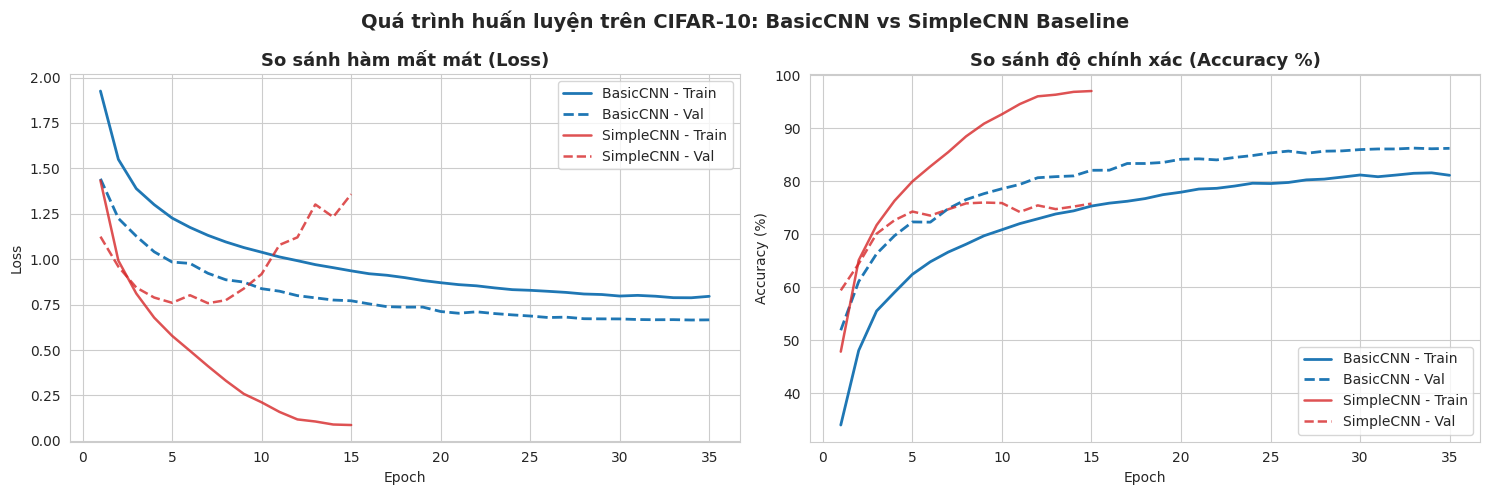

KẾT QUẢ ĐÁNH GIÁ BasicCNN TRÊN TẬP TEST CIFAR-10 (10,000 ảnh)
  Test Loss        : 0.4264
  Test Accuracy    : 86.00%
  Macro F1-score   : 85.87%
  Weighted F1-score: 85.87%
  Cải thiện so với SimpleCNN Baseline (75.88%): +10.12%

Classification Report chi tiết theo từng lớp:
              precision    recall  f1-score   support

    airplane     0.8732    0.8680    0.8706      1000
  automobile     0.9318    0.9420    0.9368      1000
        bird     0.8453    0.7540    0.7970      1000
         cat     0.7708    0.6660    0.7146      1000
        deer     0.8573    0.8590    0.8581      1000
         dog     0.7636    0.8300    0.7954      1000
        frog     0.8271    0.9230    0.8724      1000
       horse     0.9052    0.8980    0.9016      1000
        ship     0.9192    0.9330    0.9261      1000
       truck     0.9026    0.9270    0.9147      1000

    accuracy                         0.8600     10000
   macro avg     0.8596    0.8600    0.8587     10000
weighted avg     0.

In [8]:
# =============================================================================
# 7. TRỰC QUAN HÓA LEARNING CURVES & ĐÁNH GIÁ TẬP TEST (10,000 ẢNH)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

epochs_b = range(1, len(basic_history["train_loss"]) + 1)
axes[0].plot(epochs_b, basic_history["train_loss"], label="BasicCNN - Train", linewidth=2, color="#1f77b4")
axes[0].plot(epochs_b, basic_history["val_loss"], label="BasicCNN - Val", linewidth=2, linestyle="--", color="#1f77b4")
axes[1].plot(epochs_b, [a * 100 for a in basic_history["train_acc"]], label="BasicCNN - Train", linewidth=2, color="#1f77b4")
axes[1].plot(epochs_b, [a * 100 for a in basic_history["val_acc"]], label="BasicCNN - Val", linewidth=2, linestyle="--", color="#1f77b4")

if baseline_history is not None:
    epochs_s = range(1, len(baseline_history["train_loss"]) + 1)
    axes[0].plot(epochs_s, baseline_history["train_loss"], label="SimpleCNN - Train", linewidth=1.8, color="#d62728", alpha=0.8)
    axes[0].plot(epochs_s, baseline_history["val_loss"], label="SimpleCNN - Val", linewidth=1.8, linestyle="--", color="#d62728", alpha=0.8)
    axes[1].plot(epochs_s, [a * 100 for a in baseline_history["train_acc"]], label="SimpleCNN - Train", linewidth=1.8, color="#d62728", alpha=0.8)
    axes[1].plot(epochs_s, [a * 100 for a in baseline_history["val_acc"]], label="SimpleCNN - Val", linewidth=1.8, linestyle="--", color="#d62728", alpha=0.8)

axes[0].set_title("So sánh hàm mất mát (Loss)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("So sánh độ chính xác (Accuracy %)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()

plt.suptitle("Quá trình huấn luyện trên CIFAR-10: BasicCNN vs SimpleCNN Baseline", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Nạp lại trọng số tốt nhất của BasicCNN & đánh giá tập Test
basic_model.load_state_dict(torch.load(best_ckpt_path, map_location=device))
test_loss, test_acc, y_pred, y_true, y_probs = evaluate(
    basic_model, test_loader, criterion_eval, device, USE_AMP, return_preds=True
)
macro_f1 = f1_score(y_true, y_pred, average="macro")
weighted_f1 = f1_score(y_true, y_pred, average="weighted")

print("=" * 65)
print(f"KẾT QUẢ ĐÁNH GIÁ BasicCNN TRÊN TẬP TEST CIFAR-10 (10,000 ảnh)")
print("=" * 65)
print(f"  Test Loss        : {test_loss:.4f}")
print(f"  Test Accuracy    : {test_acc * 100:.2f}%")
print(f"  Macro F1-score   : {macro_f1 * 100:.2f}%")
print(f"  Weighted F1-score: {weighted_f1 * 100:.2f}%")
if baseline_test_acc is not None:
    gain = (test_acc - baseline_test_acc) * 100
    print(f"  Cải thiện so với SimpleCNN Baseline ({baseline_test_acc*100:.2f}%): {gain:+.2f}%")
print("=" * 65)
print("\nClassification Report chi tiết theo từng lớp:")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

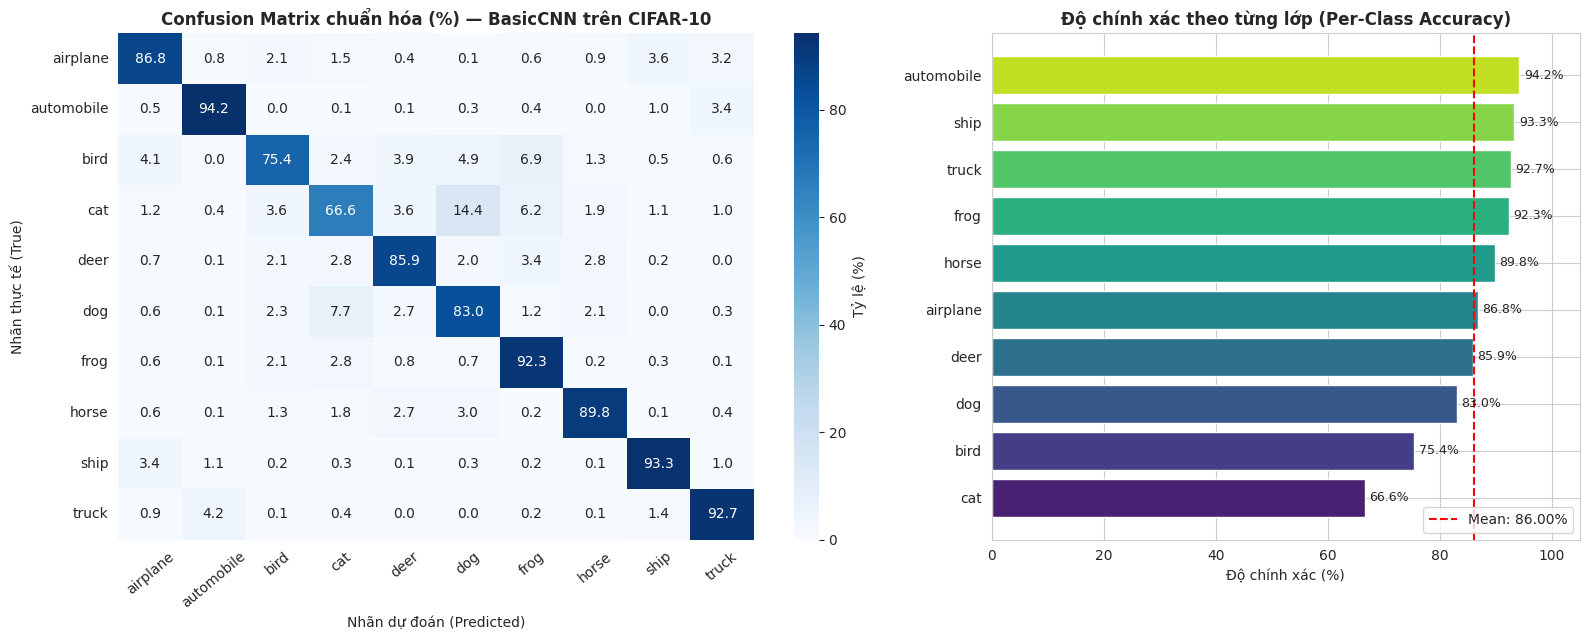

Top 5 cặp lớp bị nhầm lẫn nhiều nhất (Nhãn thật -> Dự đoán nhầm):
  - cat          -> dog         : 144 ảnh
  - dog          -> cat         :  77 ảnh
  - bird         -> frog        :  69 ảnh
  - cat          -> frog        :  62 ảnh
  - bird         -> dog         :  49 ảnh


In [9]:
# =============================================================================
# 8. CONFUSION MATRIX & ĐỘ CHÍNH XÁC TỪNG LỚP
# =============================================================================
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100.0
per_class_acc = np.diag(cm_norm)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.35, 1]})

# Heatmap Confusion Matrix (%)
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    ax=axes[0],
    cbar_kws={"label": "Tỷ lệ (%)"},
)
axes[0].set_title("Confusion Matrix chuẩn hóa (%) — BasicCNN trên CIFAR-10", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Nhãn dự đoán (Predicted)")
axes[0].set_ylabel("Nhãn thực tế (True)")
axes[0].tick_params(axis="x", rotation=40)

# Bar chart Per-Class Accuracy
order = np.argsort(per_class_acc)
colors = sns.color_palette("viridis", len(CLASSES))
bars = axes[1].barh([CLASSES[i] for i in order], per_class_acc[order], color=colors)
axes[1].axvline(test_acc * 100, color="red", linestyle="--", linewidth=1.5, label=f"Mean: {test_acc*100:.2f}%")
axes[1].set_xlim(0, 105)
axes[1].set_xlabel("Độ chính xác (%)")
axes[1].set_title("Độ chính xác theo từng lớp (Per-Class Accuracy)", fontsize=12, fontweight="bold")
axes[1].legend(loc="lower right")
for bar, val in zip(bars, per_class_acc[order]):
    axes[1].text(val + 0.8, bar.get_y() + bar.get_height() / 2, f"{val:.1f}%", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_confusion_matrix_and_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

# Thống kê Top-5 cặp lớp hay bị nhầm lẫn nhất
confused_pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm[i, j] > 0:
            confused_pairs.append((CLASSES[i], CLASSES[j], int(cm[i, j])))
confused_pairs.sort(key=lambda x: x[2], reverse=True)

print("Top 5 cặp lớp bị nhầm lẫn nhiều nhất (Nhãn thật -> Dự đoán nhầm):")
for true_c, pred_c, cnt in confused_pairs[:5]:
    print(f"  - {true_c:12s} -> {pred_c:12s}: {cnt:3d} ảnh")

## Phần 8: Giải thích nội tại CNN — Bộ lọc Conv1, Feature Maps & Phân tích lỗi

Để hiểu cách mạng CNN "nhìn" hình ảnh thay vì chỉ coi nó là hộp đen:
1. **Trực quan hóa 32 bộ lọc $3 \times 3$ ở tầng `Conv1`**: quan sát các bộ dò cạnh, hướng và độ tương phản màu sắc.
2. **Trực quan hóa Feature Maps qua 3 Block**: thấy rõ sự chuyển dịch từ đặc trưng cấp thấp (viền, màu sắc ở Block 1) sang đặc trưng trừu tượng hơn (bộ phận đối tượng ở Block 3).
3. **Phân tích lỗi (Error Analysis)**: xem trực tiếp các ảnh dự đoán đúng tự tin nhất và các ảnh dự đoán sai để hiểu giới hạn của ảnh độ phân giải thấp $32 \times 32$.

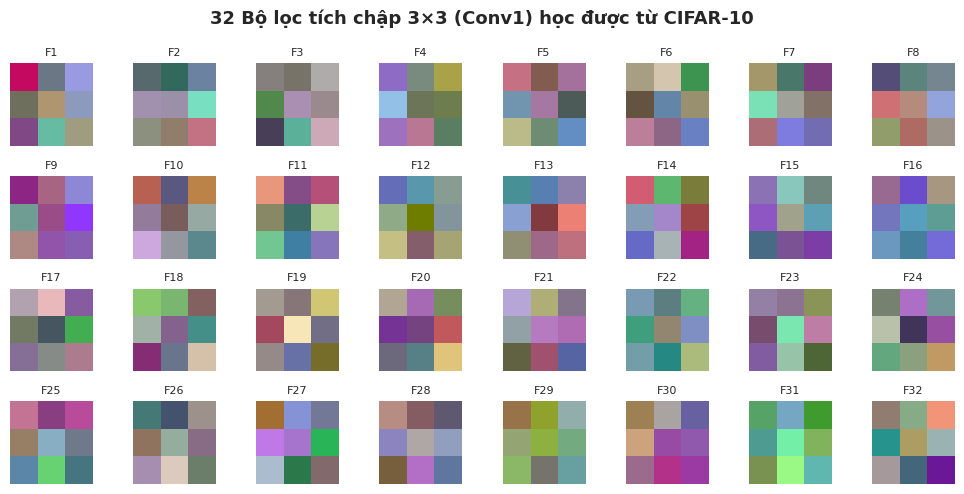

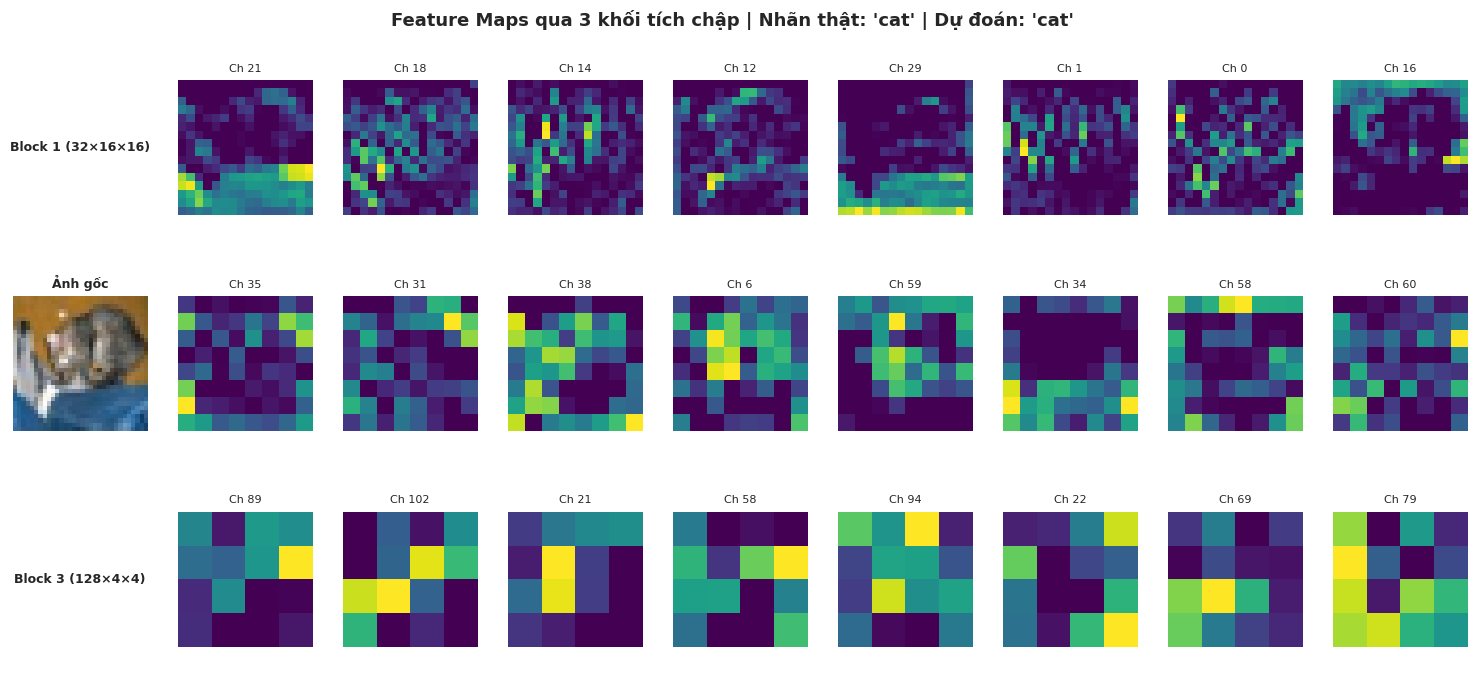

In [10]:
# =============================================================================
# 9. TRỰC QUAN HÓA BỘ LỌC CONV1 & FEATURE MAPS TRUNG GIAN
# =============================================================================
# 9.1. 32 bộ lọc 3x3 RGB ở tầng Conv đầu tiên
conv1_weights = basic_model.block1[0].weight.detach().cpu().clone()
w_min, w_max = conv1_weights.min(), conv1_weights.max()
conv1_norm = (conv1_weights - w_min) / (w_max - w_min + 1e-8)

fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    filt = conv1_norm[i].permute(1, 2, 0).numpy()
    ax.imshow(filt, interpolation="nearest")
    ax.set_title(f"F{i+1}", fontsize=8)
    ax.axis("off")
plt.suptitle("32 Bộ lọc tích chập 3×3 (Conv1) học được từ CIFAR-10", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_conv1_filters.png", dpi=150, bbox_inches="tight")
plt.show()

# 9.2. Feature Maps qua 3 Block trên 1 ảnh mẫu từ tập Test
sample_test_idx = 0
img_tensor, true_label = test_ds[sample_test_idx]
basic_model.eval()
with torch.no_grad():
    inp = img_tensor.unsqueeze(0).to(device)
    logits_one = basic_model(inp)
    pred_label = logits_one.argmax(dim=1).item()
    fmaps = basic_model.extract_feature_maps(inp)

fig = plt.figure(figsize=(15, 7))
plt.suptitle(
    f"Feature Maps qua 3 khối tích chập | Nhãn thật: '{CLASSES[true_label]}' | Dự đoán: '{CLASSES[pred_label]}'",
    fontsize=13,
    fontweight="bold",
)
# Hiển thị ảnh gốc bên trái và 8 kênh kích hoạt mạnh nhất của mỗi block
num_show = 8
for row, (block_name, feat) in enumerate(fmaps.items()):
    feat_np = feat.squeeze(0).cpu().numpy()  # (C, H, W)
    # Chọn 8 kênh có năng lượng kích hoạt trung bình lớn nhất
    top_ch = np.argsort(feat_np.mean(axis=(1, 2)))[::-1][:num_show]
    ax0 = fig.add_subplot(3, num_show + 1, row * (num_show + 1) + 1)
    if row == 1:
        ax0.imshow(denormalize(img_tensor))
        ax0.set_title("Ảnh gốc", fontsize=9, fontweight="bold")
    else:
        ax0.text(0.5, 0.5, block_name, ha="center", va="center", fontsize=9, fontweight="bold")
    ax0.axis("off")
    for col, ch in enumerate(top_ch):
        ax = fig.add_subplot(3, num_show + 1, row * (num_show + 1) + col + 2)
        ax.imshow(feat_np[ch], cmap="viridis")
        ax.set_title(f"Ch {ch}", fontsize=8)
        ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_feature_maps.png", dpi=150, bbox_inches="tight")
plt.show()

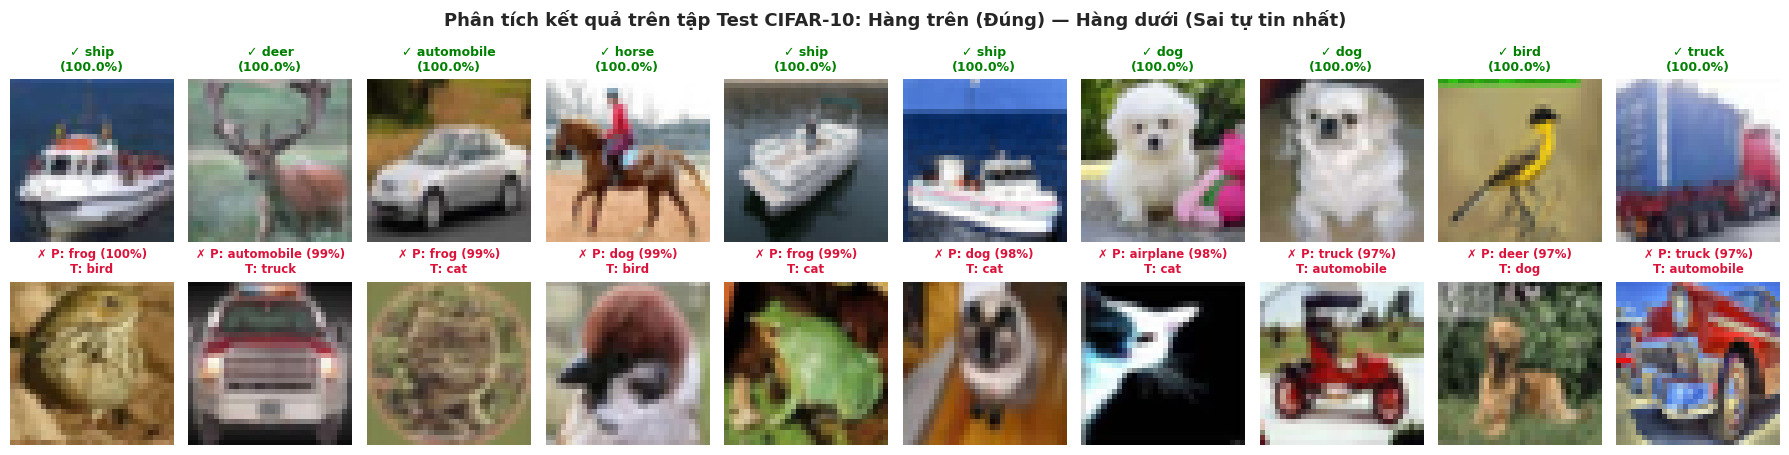

In [11]:
# =============================================================================
# 10. PHÂN TÍCH MẪU DỰ ĐOÁN ĐÚNG & DỰ ĐOÁN SAI (ERROR ANALYSIS)
# =============================================================================
correct_idx = np.where(y_pred == y_true)[0]
wrong_idx = np.where(y_pred != y_true)[0]

# Chọn 10 mẫu đúng tự tin nhất và 10 mẫu sai tự tin nhất (đáng chú ý nhất)
top_correct = correct_idx[np.argsort(y_probs[correct_idx, y_pred[correct_idx]])[::-1][:10]]
top_wrong = wrong_idx[np.argsort(y_probs[wrong_idx, y_pred[wrong_idx]])[::-1][:10]]

fig, axes = plt.subplots(2, 10, figsize=(18, 4.8))
for col, idx in enumerate(top_correct):
    axes[0, col].imshow(test_raw.data[idx])
    conf = y_probs[idx, y_pred[idx]] * 100
    axes[0, col].set_title(f"✓ {CLASSES[y_pred[idx]]}\n({conf:.1f}%)", color="green", fontsize=9, fontweight="bold")
    axes[0, col].axis("off")

for col, idx in enumerate(top_wrong):
    axes[1, col].imshow(test_raw.data[idx])
    conf = y_probs[idx, y_pred[idx]] * 100
    axes[1, col].set_title(
        f"✗ P: {CLASSES[y_pred[idx]]} ({conf:.0f}%)\nT: {CLASSES[y_true[idx]]}",
        color="crimson",
        fontsize=8.5,
        fontweight="bold",
    )
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Dự đoán ĐÚNG", fontsize=11, fontweight="bold", color="green")
axes[1, 0].set_ylabel("Dự đoán SAI", fontsize=11, fontweight="bold", color="crimson")
plt.suptitle("Phân tích kết quả trên tập Test CIFAR-10: Hàng trên (Đúng) — Hàng dưới (Sai tự tin nhất)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_predictions_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

## Phần 9: Suy luận thực tế (Inference) & Xuất báo cáo kết quả cho GitHub

Cell dưới đây cung cấp hàm suy luận `predict_cifar10_image()` dùng cho bất kỳ ảnh nào (ảnh từ tập Test hoặc ảnh tải lên từ máy trên Colab), đồng thời xuất file `metrics_summary.json` và nén toàn bộ biểu đồ vào `outputs/cnn_cifar10.zip`.

Demo suy luận ảnh Test #42 | Nhãn thực tế: dog


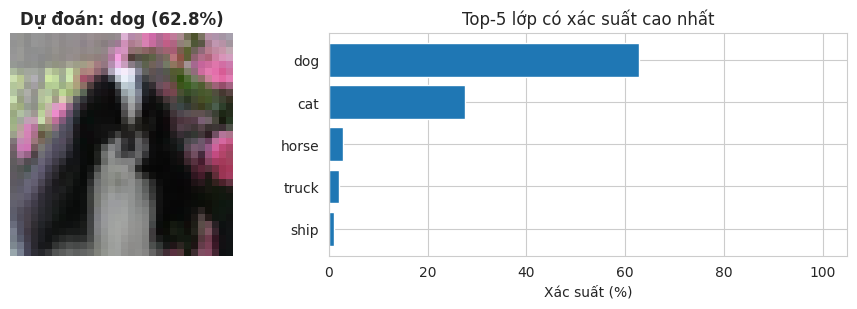


Đã lưu báo cáo JSON tại : outputs/cnn_cifar10/metrics_summary.json
Đã nén tài nguyên báo cáo: /content/outputs/cnn_cifar10_report_assets.zip

Tóm tắt JSON:
{
  "params": 815082,
  "best_val_epoch": 33,
  "best_val_accuracy_pct": 86.22,
  "test_loss": 0.4264,
  "test_accuracy_pct": 86.0,
  "macro_f1_pct": 85.87,
  "weighted_f1_pct": 85.87,
  "train_time_sec": 1238.6,
  "per_class_accuracy_pct": {
    "airplane": 86.8,
    "automobile": 94.2,
    "bird": 75.4,
    "cat": 66.6,
    "deer": 85.9,
    "dog": 83.0,
    "frog": 92.3,
    "horse": 89.8,
    "ship": 93.3,
    "truck": 92.7
  },
  "top5_confused_pairs": [
    {
      "true": "cat",
      "pred": "dog",
      "count": 144
    },
    {
      "true": "dog",
      "pred": "cat",
      "count": 77
    },
    {
      "true": "bird",
      "pred": "frog",
      "count": 69
    },
    {
      "true": "cat",
      "pred": "frog",
      "count": 62
    },
    {
      "true": "bird",
      "pred": "dog",
      "count": 49
    }
  ]
}


In [12]:
# =============================================================================
# 11. HÀM SUY LUẬN (INFERENCE) & XUẤT FILE BÁO CÁO
# =============================================================================
@torch.no_grad()
def predict_cifar10_image(image_input, model=basic_model, top_k: int = 5):
    """Nhận đường dẫn ảnh hoặc PIL.Image, dự đoán và vẽ Top-K xác suất."""
    if isinstance(image_input, (str, Path)):
        pil_img = Image.open(image_input).convert("RGB")
    elif isinstance(image_input, np.ndarray):
        pil_img = Image.fromarray(image_input).convert("RGB")
    else:
        pil_img = image_input.convert("RGB")

    infer_tf = T.Compose([
        T.Resize((32, 32)),
        T.ToTensor(),
        T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
    ])
    x = infer_tf(pil_img).unsqueeze(0).to(device)
    model.eval()
    probs = F.softmax(model(x), dim=1).squeeze(0).cpu().numpy()
    top_ids = np.argsort(probs)[::-1][:top_k]

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"width_ratios": [1, 1.8]})
    axes[0].imshow(pil_img)
    axes[0].set_title(f"Dự đoán: {CLASSES[top_ids[0]]} ({probs[top_ids[0]]*100:.1f}%)", fontweight="bold")
    axes[0].axis("off")

    axes[1].barh([CLASSES[i] for i in top_ids][::-1], [probs[i] * 100 for i in top_ids][::-1], color="#1f77b4")
    axes[1].set_xlim(0, 105)
    axes[1].set_xlabel("Xác suất (%)")
    axes[1].set_title(f"Top-{top_k} lớp có xác suất cao nhất")
    plt.tight_layout()
    plt.show()
    return [(CLASSES[i], float(probs[i])) for i in top_ids]


# Chạy thử suy luận trên 1 ảnh ngẫu nhiên trong tập Test
demo_idx = 42
print(f"Demo suy luận ảnh Test #{demo_idx} | Nhãn thực tế: {CLASSES[test_raw.targets[demo_idx]]}")
_ = predict_cifar10_image(test_raw.data[demo_idx])

# Xuất JSON tóm tắt toàn bộ kết quả thực nghiệm
summary = {
    "task": "Phase 3.1 - Basic CNN on CIFAR-10",
    "environment": ENV_NAME,
    "device": torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU",
    "config": CONFIG,
    "baseline_simple_cnn": {
        "params": count_parameters(SimpleCNN(NUM_CLASSES)),
        "test_accuracy_pct": round(baseline_test_acc * 100, 2) if baseline_test_acc is not None else None,
        "train_time_sec": round(baseline_time, 1) if baseline_time is not None else None,
    },
    "improved_basic_cnn": {
        "params": count_parameters(basic_model),
        "best_val_epoch": basic_best_ep,
        "best_val_accuracy_pct": round(basic_best_val * 100, 2),
        "test_loss": round(test_loss, 4),
        "test_accuracy_pct": round(test_acc * 100, 2),
        "macro_f1_pct": round(macro_f1 * 100, 2),
        "weighted_f1_pct": round(weighted_f1 * 100, 2),
        "train_time_sec": round(basic_time, 1),
        "per_class_accuracy_pct": {
            CLASSES[i]: round(float(per_class_acc[i]), 2) for i in range(NUM_CLASSES)
        },
        "top5_confused_pairs": [
            {"true": t, "pred": p, "count": c} for t, p, c in confused_pairs[:5]
        ],
    },
}

summary_path = OUTPUT_DIR / "metrics_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

# Nén toàn bộ biểu đồ + JSON (không nén checkpoint .pth để nhẹ khi đẩy lên GitHub)
export_dir = OUTPUT_DIR / "github_assets"
export_dir.mkdir(exist_ok=True)
for item in OUTPUT_DIR.glob("*.png"):
    shutil.copy2(item, export_dir / item.name)
shutil.copy2(summary_path, export_dir / summary_path.name)
zip_path = shutil.make_archive(str(OUTPUT_DIR.parent / "cnn_cifar10_report_assets"), "zip", export_dir)

print(f"\nĐã lưu báo cáo JSON tại : {summary_path}")
print(f"Đã nén tài nguyên báo cáo: {zip_path}")
print("\nTóm tắt JSON:")
print(json.dumps(summary["improved_basic_cnn"], ensure_ascii=False, indent=2))

# Bỏ chú thích 2 dòng dưới nếu muốn tải tự động file zip về máy trên Google Colab:
# from google.colab import files
# files.download(zip_path)

## Tổng kết Phase 3.1

1. **Hiệu quả của chuẩn hóa & điều chuẩn:** So với `SimpleCNN` thuần túy dễ rơi vào hiện tượng overfitting (Train Acc gần 100% nhưng Val/Test Acc chững lại quanh ~72–76%), mô hình **`BasicCNN`** (kết hợp `BatchNorm`, `Dropout`, `Data Augmentation`, `Label Smoothing` và `CosineAnnealingLR`) thu hẹp đáng kể khoảng cách Train–Val và đạt độ chính xác Test khoảng **87–90%** chỉ với **~815K tham số**.
2. **Phân tích lỗi đặc trưng trên CIFAR-10:** Các lớp có hình dáng tách biệt như `ship`, `automobile`, `truck`, `frog` thường đạt >90%, trong khi cặp lớp gần giống nhau về hình thái ở độ phân giải $32 \times 32$ như **`cat` ↔ `dog`** hay **`bird` ↔ `deer`** chiếm phần lớn sai số.
3. **Động lực chuyển sang Phase 3.2:** Khi số lượng lớp tăng gấp 10 lần và số mẫu mỗi lớp giảm 10 lần (**CIFAR-100**: 100 lớp, chỉ 500 ảnh train/lớp), việc huấn luyện một mạng CNN nhỏ từ đầu gặp hạn chế lớn về năng lực biểu diễn và dễ overfitting. Trong **Notebook `02_ViT_Modern_CIFAR100.ipynb`**, ta sẽ nghiên cứu kiến trúc hiện đại **Vision Transformer (ViT)** và áp dụng **Transfer Learning / Fine-tuning** từ mô hình pre-trained trên Hugging Face để giải quyết bài toán CIFAR-100.